## Кластеризация и визуализация с помощью главных компонент

In [1]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns

Подгрузка данных 

In [2]:
df = pd.read_csv('bank-additional-full.csv', sep = ';')
# Этот код фильтрует строки в df таким образом, чтобы остались только те строки, 
# у которых нет в любой из колонок значения 'unknown'.
df_fl = df[~df.apply(lambda x: x.isin(['unknown']).any(), axis=1)]
df_fl

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
6,59,admin.,married,professional.course,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes


In [3]:
df

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes


Выбор признаков для анализа

In [4]:
df_cl = df_fl[['job', 'education', 'marital', 'cons.price.idx', 'emp.var.rate']]
df_cl

,job,education,marital,cons.price.idx,emp.var.rate
0,housemaid,basic.4y,married,93.994,1.1
2,services,high.school,married,93.994,1.1
3,admin.,basic.6y,married,93.994,1.1
4,services,high.school,married,93.994,1.1
6,admin.,professional.course,married,93.994,1.1
...,...,...,...,...,...
41183,retired,professional.course,married,94.767,-1.1
41184,blue-collar,professional.course,married,94.767,-1.1
41185,retired,university.degree,married,94.767,-1.1
41186,technician,professional.course,married,94.767,-1.1


Было выбрано 3 категориальных признака: должность (работа), образорвание и семейное положение. Числовые признаки: индекс потребительских цен и индекс изменения занятости.

Кодировка категориальных признаков

In [5]:
df_dm = pd.get_dummies(df_cl, columns=['job', 'education', 'marital'])
df_dm

,cons.price.idx,emp.var.rate,job_admin.,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,...,education_basic.4y,education_basic.6y,education_basic.9y,education_high.school,education_illiterate,education_professional.course,education_university.degree,marital_divorced,marital_married,marital_single
0,93.994,1.1,False,False,False,True,False,False,False,False,...,True,False,False,False,False,False,False,False,True,False
2,93.994,1.1,False,False,False,False,False,False,False,True,...,False,False,False,True,False,False,False,False,True,False
3,93.994,1.1,True,False,False,False,False,False,False,False,...,False,True,False,False,False,False,False,False,True,False
4,93.994,1.1,False,False,False,False,False,False,False,True,...,False,False,False,True,False,False,False,False,True,False
6,93.994,1.1,True,False,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,94.767,-1.1,False,False,False,False,False,True,False,False,...,False,False,False,False,False,True,False,False,True,False
41184,94.767,-1.1,False,True,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,True,False
41185,94.767,-1.1,False,False,False,False,False,True,False,False,...,False,False,False,False,False,False,True,False,True,False
41186,94.767,-1.1,False,False,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,True,False


Удаление признаков с высокой корреляцией

<Axes: >

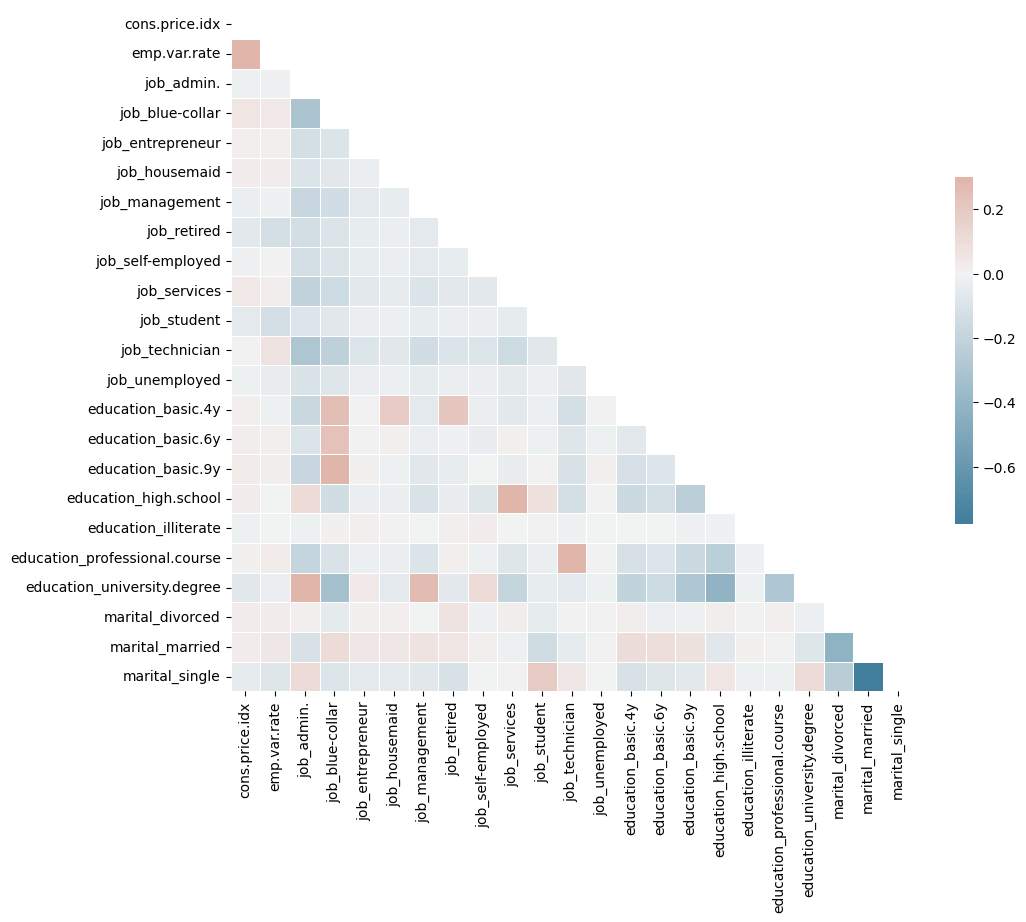

In [6]:
corr = df_dm.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
f, ax = plt.subplots(figsize=(11, 9))
cmap = sns.diverging_palette(230, 20, as_cmap=True)
sns.heatmap(corr, mask=mask, cmap=cmap, vmax=.3, center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .5})

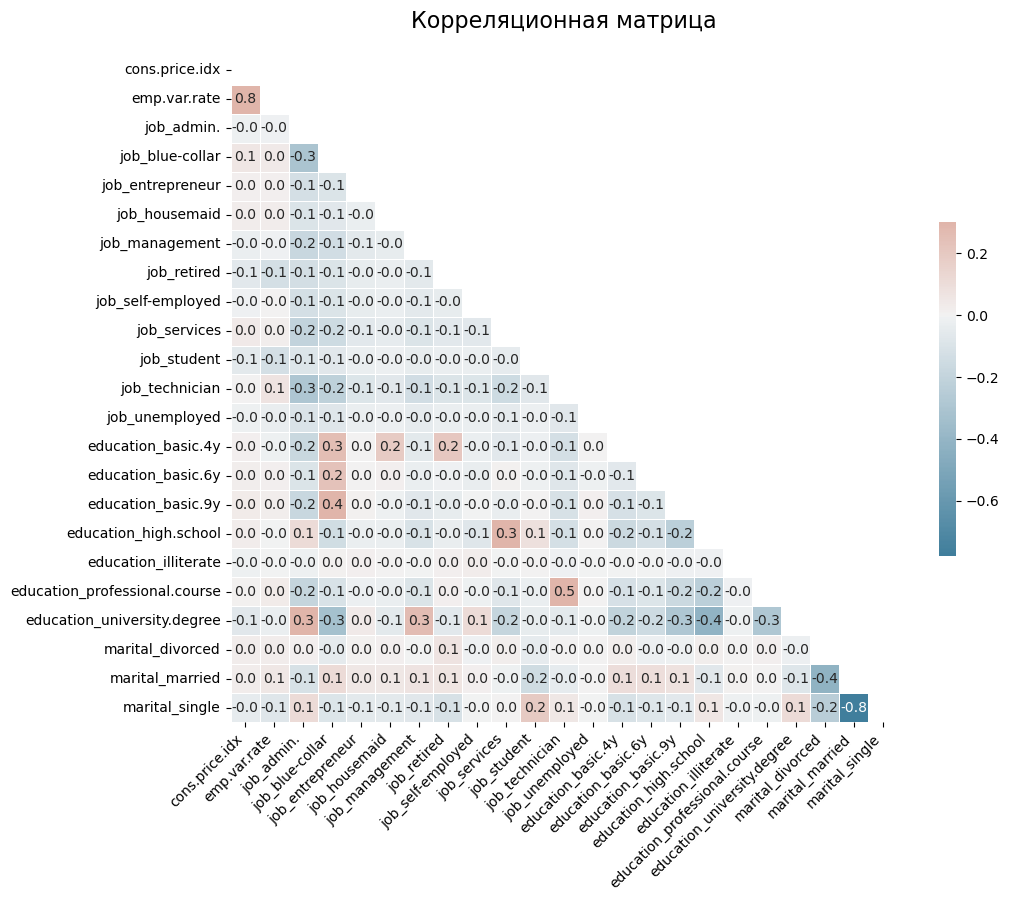

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Рассчитываем корреляционную матрицу
corr = df_dm.corr()

# Создаем маску для верхнего треугольника
mask = np.triu(np.ones_like(corr, dtype=bool))

# Настраиваем график
f, ax = plt.subplots(figsize=(11, 9))
cmap = sns.diverging_palette(230, 20, as_cmap=True)

# Строим тепловую карту с аннотациями
sns.heatmap(corr, 
            mask=mask, 
            cmap=cmap, 
            vmax=.3, 
            center=0,
            square=True, 
            linewidths=.5, 
            cbar_kws={"shrink": .5},
            annot=True,  # Добавляем цифры
            fmt=".1f",   # Формат чисел: 2 знака после запятой
            annot_kws={"size": 10})  # Размер шрифта цифр

# Настраиваем внешний вид
plt.title('Корреляционная матрица', fontsize=16, pad=20)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()

plt.show()

Сильной корреляционной связью считаем 0,8, соответственно выберем признаки между которыми возникла мультиколлинеарность и удалим их. Удаляем: marital_single, emp.var.rate..

In [8]:
df_dm= df_dm.drop(columns=["marital_single","emp.var.rate"])

In [9]:
df_dm

,cons.price.idx,job_admin.,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,job_student,...,job_unemployed,education_basic.4y,education_basic.6y,education_basic.9y,education_high.school,education_illiterate,education_professional.course,education_university.degree,marital_divorced,marital_married
0,93.994,False,False,False,True,False,False,False,False,False,...,False,True,False,False,False,False,False,False,False,True
2,93.994,False,False,False,False,False,False,False,True,False,...,False,False,False,False,True,False,False,False,False,True
3,93.994,True,False,False,False,False,False,False,False,False,...,False,False,True,False,False,False,False,False,False,True
4,93.994,False,False,False,False,False,False,False,True,False,...,False,False,False,False,True,False,False,False,False,True
6,93.994,True,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,True,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,94.767,False,False,False,False,False,True,False,False,False,...,False,False,False,False,False,False,True,False,False,True
41184,94.767,False,True,False,False,False,False,False,False,False,...,False,False,False,False,False,False,True,False,False,True
41185,94.767,False,False,False,False,False,True,False,False,False,...,False,False,False,False,False,False,False,True,False,True
41186,94.767,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,True,False,False,True


Анализ методом главных компонентов (PCA)

In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

scaler = StandardScaler()
df_std = scaler.fit_transform(df_dm)

pca = PCA()
df_pca = pca.fit_transform(df_std)

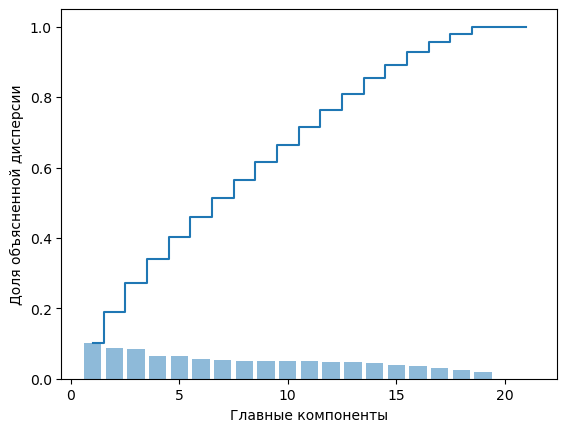

In [11]:
plt.bar(range(1, df_dm.shape[1] + 1), pca.explained_variance_ratio_, alpha=0.5, align='center')
plt.step(range(1, df_dm.shape[1] + 1), np.cumsum(pca.explained_variance_ratio_), where='mid')
plt.ylabel('Доля объясненной дисперсии')
plt.xlabel('Главные компоненты')
plt.show()

In [12]:
# Определение важных признаков для 3 главных компонент с наибольше вариацией
for i, component in enumerate(pca.components_[:3]):
    print(f'\nГлавная компонента {i+1}:')
    indices = np.argsort(np.abs(component))[::-1]
    for j, index in enumerate(indices[:5]):
        print(f'  {j+1}. {df_dm.columns[index]} ({component[index]:.2f})')


Главная компонента 1:
  1. job_blue-collar (0.51)
  2. education_university.degree (-0.48)
  3. job_admin. (-0.41)
  4. education_basic.9y (0.35)
  5. education_basic.4y (0.27)

Главная компонента 2:
  1. job_technician (0.63)
  2. education_professional.course (0.62)
  3. job_admin. (-0.26)
  4. education_high.school (-0.24)
  5. job_blue-collar (-0.17)

Главная компонента 3:
  1. education_high.school (0.59)
  2. job_services (0.45)
  3. education_university.degree (-0.42)
  4. job_management (-0.26)
  5. marital_married (-0.23)


Вывод: При выполнении метода было получено 3 главные компоненты, состав которых приведен выше. Как можно также заметить на графике выше, наибольшую описательную способность дисперсии из имеющихся возможных (0.15) имеют первые две компоненты, соответственно именно они будт использоваться для дальнейшего анализа. Коэффициент показывает, что дисперсия описывается компонентами только на 15%, что является плохим результатом. 

Кластеризация методом к-средних

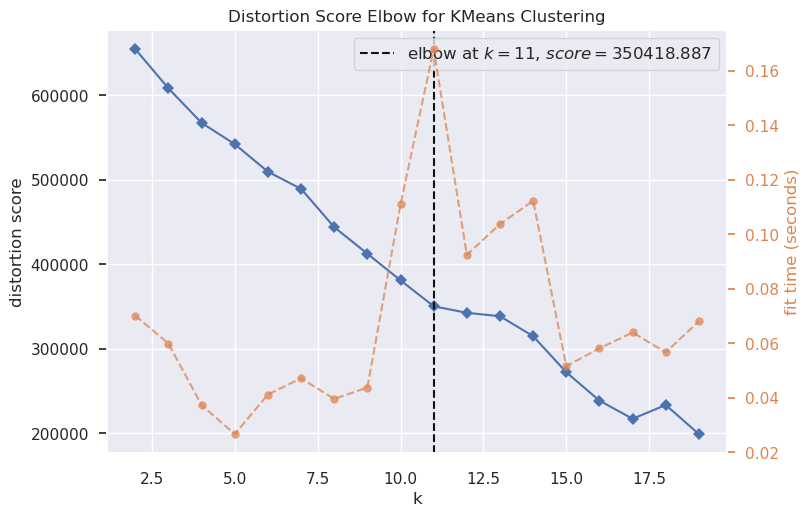

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [36]:
from yellowbrick.cluster import KElbowVisualizer
# определение оптимального числа кластеров
model = KMeans()
# создается объект `KElbowVisualizer`, который позволяет нам определить оптимальное количество кластеров. 
# Параметр `k` указывает диапазон числа кластеров, который мы хотим исследовать.
visualizer = KElbowVisualizer(model, k=(2,20), random_state=16) # https://www.scikit-yb.org/en/latest/api/cluster/elbow.html
# Метод `fit()` принимает набор данных `df_std` и подгоняет модель к этим данным.
visualizer.fit(df_std)
visualizer.show()

In [14]:
kmeans = KMeans(n_clusters=11)
kmeans.fit(df_std)
cluster_labels = kmeans.labels_

Вывод: при анализе методом к-средних было выявлено оптимальное количество кластеров - 11, с помощью метода KElbowVisualizer. Обработанные данные были распределены соответсвенно по данным найденным кластерам.

Описание кластеров

In [15]:
cluster_labels

array([7, 4, 8, ..., 6, 3, 3], shape=(30488,), dtype=int32)

In [16]:
df_dm['clusters'] = cluster_labels

In [17]:
# группировка данных по столбцу кластеры, отберите только 3 основных признака
grouped = df_dm[['clusters','job_blue-collar', 'job_technician', 'education_high.school']].groupby('clusters')
# Сводная статистика для остальных столбцов
summary = grouped.agg(['mean', 'max', 'min', 'count', 'sum'])
summary

job_blue-collar                     job_technician                \
                    mean    max    min count           mean    max    min   
clusters                                                                    
0               0.693025   True  False  2466       0.081914   True  False   
1               0.661485   True  False  1158       0.100173   True  False   
2               0.000000  False  False  2257       0.000000  False  False   
3               0.091931   True  False  3916       0.708376   True  False   
4               0.000000  False  False  2640       0.000000  False  False   
5               0.135644   True  False  5050       0.146931   True  False   
6               0.008996   True  False  7670       0.201434   True  False   
7               0.554574   True  False  2263       0.014582   True  False   
8               0.608346   True  False  1366       0.044656   True  False   
9               0.000000  False  False  1092       0.000000  False  False   
10              0.000000  False  False   610       0.000000  False  False   

               education_high.school                      
         count                  mean    max    min count  
clusters                                                  
0         2466              0.000000  False  False  2466  
1         1158              0.000000  False  False  1158  
2         2257              0.096145   True  False  2257  
3         3916              0.000000  False  False  3916  
4         2640              0.766667   True  False  2640  
5         5050              1.000000   True   True  5050  
6         7670              0.000000  False  False  7670  
7         2263              0.000000  False  False  2263  
8         1366              0.000000  False  False  1366  
9         1092              0.083333   True  False  1092  
10         610              0.519672   True  False   610

Вывод: Кластеры были сгруппированы по основным признакам, выбранным с помощью метода основных компонент. (Основные признаки - наиболее важные признаки в каждой из 3-х компонент.)

Визуализация кластеров по двум главным компонентам

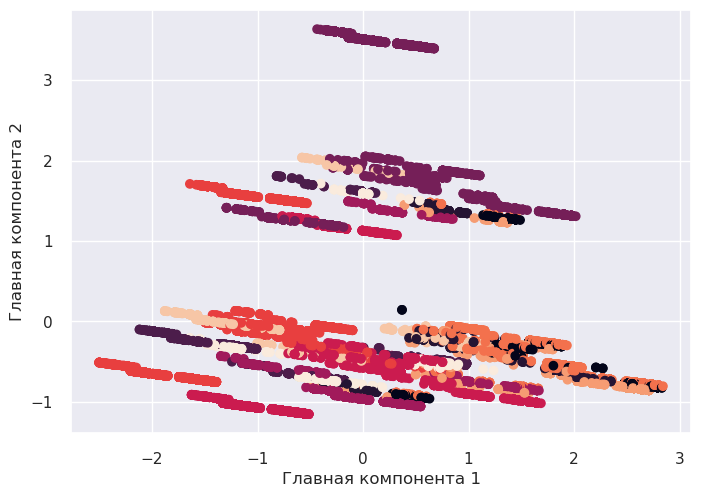

In [18]:
sns.set()
plt.scatter(df_pca[:, 0], df_pca[:, 1], c=cluster_labels)
plt.xlabel('Главная компонента 1')
plt.ylabel('Главная компонента 2')
plt.show()

Вывод: Так как две главные компоненты описывают только около 15% процентов дисперсии, построенный в двухмерном пространстве график является малоинформативным. На графике видно, что 11 полученных кластеров накладываются друг на друга, и формируются 3 кластера, то есть отражаются 3 кластера, вместо правильных 11.

Если бы 2 главные компоненты отражали  100% дисперсии, то на графике были ли бы выделены все 11 кластеров.

***Анализ без 3 пункта - без удаления мультиколлинеарности***

Отобранные раннее признаки также остаются

In [19]:
df_cl

,job,education,marital,cons.price.idx,emp.var.rate
0,housemaid,basic.4y,married,93.994,1.1
2,services,high.school,married,93.994,1.1
3,admin.,basic.6y,married,93.994,1.1
4,services,high.school,married,93.994,1.1
6,admin.,professional.course,married,93.994,1.1
...,...,...,...,...,...
41183,retired,professional.course,married,94.767,-1.1
41184,blue-collar,professional.course,married,94.767,-1.1
41185,retired,university.degree,married,94.767,-1.1
41186,technician,professional.course,married,94.767,-1.1


In [20]:
df_dm = pd.get_dummies(df_cl, columns=['job', 'education', 'marital'])
df_dm 

,cons.price.idx,emp.var.rate,job_admin.,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,...,education_basic.4y,education_basic.6y,education_basic.9y,education_high.school,education_illiterate,education_professional.course,education_university.degree,marital_divorced,marital_married,marital_single
0,93.994,1.1,False,False,False,True,False,False,False,False,...,True,False,False,False,False,False,False,False,True,False
2,93.994,1.1,False,False,False,False,False,False,False,True,...,False,False,False,True,False,False,False,False,True,False
3,93.994,1.1,True,False,False,False,False,False,False,False,...,False,True,False,False,False,False,False,False,True,False
4,93.994,1.1,False,False,False,False,False,False,False,True,...,False,False,False,True,False,False,False,False,True,False
6,93.994,1.1,True,False,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,94.767,-1.1,False,False,False,False,False,True,False,False,...,False,False,False,False,False,True,False,False,True,False
41184,94.767,-1.1,False,True,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,True,False
41185,94.767,-1.1,False,False,False,False,False,True,False,False,...,False,False,False,False,False,False,True,False,True,False
41186,94.767,-1.1,False,False,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,True,False


Никакие из признаков обработанных выбранных данных не удаляются

Метод главных компонент

In [21]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

scaler = StandardScaler()
df_std = scaler.fit_transform(df_dm)

pca = PCA()
df_pca = pca.fit_transform(df_std)

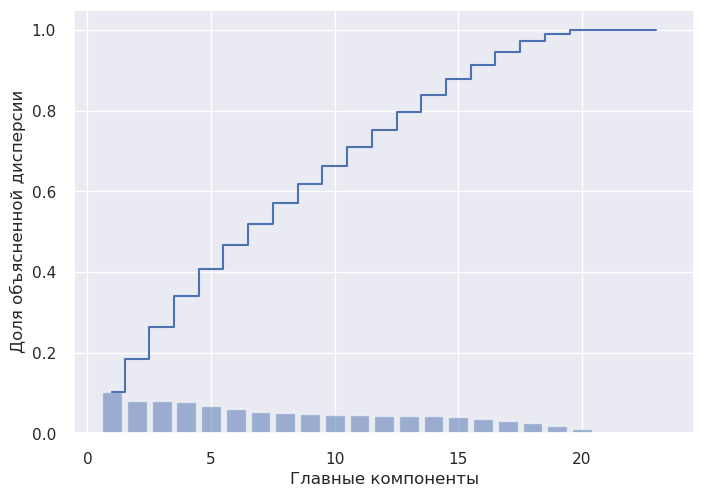

In [22]:
plt.bar(range(1, df_dm.shape[1] + 1), pca.explained_variance_ratio_, alpha=0.5, align='center')
plt.step(range(1, df_dm.shape[1] + 1), np.cumsum(pca.explained_variance_ratio_), where='mid')
plt.ylabel('Доля объясненной дисперсии')
plt.xlabel('Главные компоненты')
plt.show()

In [23]:
for i, component in enumerate(pca.components_[:3]):
    print(f'\nГлавная компонента {i+1}:')
    indices = np.argsort(np.abs(component))[::-1]
    for j, index in enumerate(indices[:5]):
        print(f'  {j+1}. {df_dm.columns[index]} ({component[index]:.2f})')


Главная компонента 1:
  1. marital_married (0.41)
  2. job_blue-collar (0.40)
  3. marital_single (-0.40)
  4. education_university.degree (-0.36)
  5. job_admin. (-0.33)

Главная компонента 2:
  1. job_technician (0.39)
  2. emp.var.rate (0.38)
  3. cons.price.idx (0.38)
  4. education_professional.course (0.37)
  5. education_university.degree (-0.33)

Главная компонента 3:
  1. education_high.school (0.44)
  2. education_university.degree (-0.37)
  3. job_technician (-0.35)
  4. job_services (0.32)
  5. education_professional.course (-0.31)


Вывод: При выполнении метода также было получено 3 главные компоненты, состав которых приведен выше. Как можно заметить на графике выше, наибольшую описательную способность дисперсии из имеющихся возможных (0.15) имеют первые две компоненты, соответственно именно они будт использоваться для дальнейшего анализа. Коэффициент показывает, что дисперсия описывается главными компонентами также только на 15%, что является плохим результатом. Влияние мультиколлинеарности крайне мало.

Метод К средних (Кластеризация)

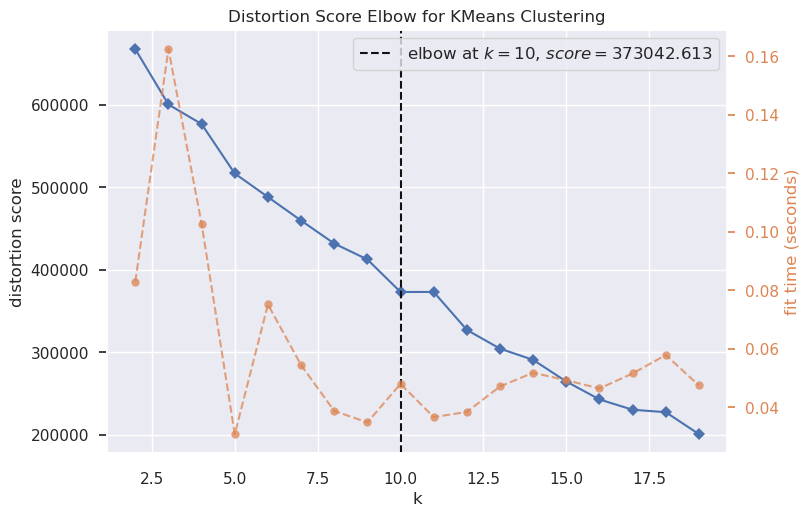

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [52]:
from yellowbrick.cluster import KElbowVisualizer
# определение оптимального числа кластеров
model = KMeans()
# создается объект `KElbowVisualizer`, который позволяет нам определить оптимальное количество кластеров. 
# Параметр `k` указывает диапазон числа кластеров, который мы хотим исследовать.
visualizer = KElbowVisualizer(model, k=(2, 20), random_state = 21) # https://www.scikit-yb.org/en/latest/api/cluster/elbow.html
# Метод `fit()` принимает набор данных `df_std` и подгоняет модель к этим данным.
visualizer.fit(df_std)
visualizer.show()

In [25]:
kmeans = KMeans(n_clusters=10)
kmeans.fit(df_std)
cluster_labels = kmeans.labels_

Вывод: При выполнении метода было получено оптимальное количество кластеров - 10. Обработанные данные, с учетом признаков с сильной корреляционной связью, были также распределены по ним. Как  можно заметить, включение признаков с мультиколлинеарностью, также не сильно повляло на распределение кластеров.

Описание кластеров, полученных без удаления мультиколлинеарности

In [26]:
df_dm['clusters'] = cluster_labels

In [27]:
# группировка данных по столбцу кластеры, отберите только 3 основных признака
grouped = df_dm[['clusters','marital_married', 'job_technician', 'education_high.school']].groupby('clusters')
# Сводная статистика для остальных столбцов
summary = grouped.agg(['mean', 'max', 'min', 'count'])
summary

marital_married                     job_technician                \
                    mean    max    min count           mean    max    min   
clusters                                                                    
0               0.714141   True  False  3960       0.080303   True  False   
1               0.537128   True  False  2653       0.000000  False  False   
2               0.000000  False  False  5315       0.184196   True  False   
3               0.692069   True  False  2257       0.000000  False  False   
4               0.809233   True  False  7538       0.173521   True  False   
5               0.721217   True  False  1216       0.000000  False  False   
6               0.786466   True  False  1330       0.045865   True  False   
7               0.054098   True  False   610       0.000000  False  False   
8               0.590824   True  False  3749       0.739931   True  False   
9               0.755914   True  False  1860       0.017742   True  False   

               education_high.school                      
         count                  mean    max    min count  
clusters                                                  
0         3960              0.098485   True  False  3960  
1         2653              0.762910   True  False  2653  
2         5315              0.325494   True  False  5315  
3         2257              0.096145   True  False  2257  
4         7538              0.372115   True  False  7538  
5         1216              0.177632   True  False  1216  
6         1330              0.000000  False  False  1330  
7          610              0.519672   True  False   610  
8         3749              0.000000  False  False  3749  
9         1860              0.000000  False  False  1860

Вывод: Кластеры были сгруппированы по основным признакам, выбранным с помощью метода основных компонент. При включении мультиколлинеарность один из главных признаков изменился с job_blue-collar	на marital_married.

Визуализация кластеров по двум копонентам

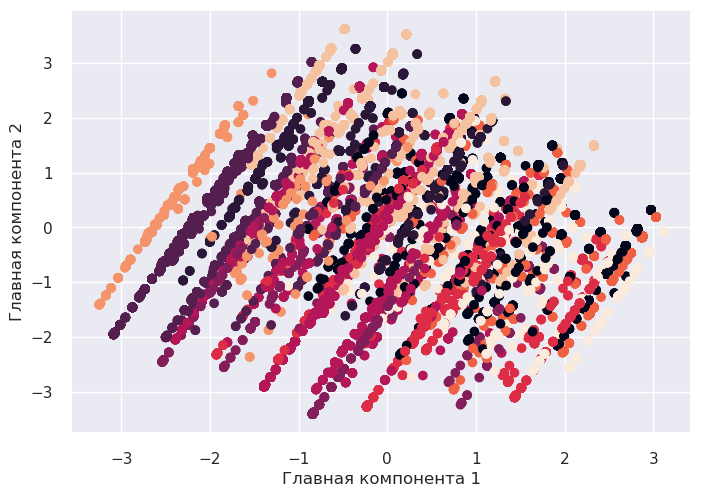

In [28]:
sns.set()
plt.scatter(df_pca[:, 0], df_pca[:, 1], c=cluster_labels)
plt.xlabel('Главная компонента 1')
plt.ylabel('Главная компонента 2')
plt.show()

При визуализации кластеров по двум компонентам, также были получены неудовлетворительные результаты. Две главные компоненты также описывают только около 15% процентов дисперсии, так что построенный в двухмерном пространстве график является малоинформативным. На графике, также как и на предыдущем, можно заметить, что 10 полученных кластеров накладываются друг на друга.

Вывод: Проведя работу можно сделать вывод о том, что для имеющихся признаков данный анализ является неподходящим, так как дает плохие результаты. При включении  мультиколлинеарности, изменения в проведении методов являются незначительными. Распределение кластеров по компонентам также показало плохие результаты в обоих случаях, кластеры не отделены друг от друга визуально, а накладываются друг на друга.